# Import packages & Load functions and data

In [ ]:
import os, glob, pysam, subprocess
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from sklearn.preprocessing import StandardScaler

In [38]:
def window_edges(length: int) -> np.ndarray:
    return np.arange(0, length + BIN_SIZE, BIN_SIZE)


def load_sample(cnr_path: str) -> pd.DataFrame:
    df = pd.read_csv(cnr_path, sep="\t")
    df = df[df["chromosome"].isin(CHROMS)].copy()
    if "weight" in df.columns:
        df = df[df["weight"] > 0]          # drop zero-weight/filtered bins
    return df


def project_segments(cns_path: str, cnr: pd.DataFrame) -> pd.DataFrame:
    """Replace each bin's log2 with the log2 of its overlapping segment."""
    cns = pd.read_csv(cns_path, sep="\t")
    cnr = cnr.copy()
    for _, seg in cns.iterrows():
        m = (
            (cnr["chromosome"] == seg["chromosome"])
            & (cnr["start"] >= seg["start"])
            & (cnr["end"] <= seg["end"])
        )
        cnr.loc[m, "log2"] = seg["log2"]
    return cnr


def binned_profile(df: pd.DataFrame, chrom: str, edges: np.ndarray):
    sub = df[df["chromosome"] == chrom]
    mids = (sub["start"] + sub["end"]) / 2
    idx = np.clip(np.digitize(mids, edges) - 1, 0, len(edges) - 2)
    out = np.full(len(edges) - 1, np.nan)
    for i, grp in sub.groupby(idx):
        out[i] = grp["log2"].median()
    return out


def visualize_main():
    cnr_paths = sorted(glob.glob(os.path.join(DIR_cnvkit_fix_out, "*.cnr")))
    if not cnr_paths:
        raise SystemExit(f"No .cnr files found in {DIR_cnvkit_fix_out}")
    sample_ids = [os.path.basename(p).replace(".cnr", "") for p in cnr_paths]

    # row order
    if SAMPLE_ORDER:
        order = [s for s in SAMPLE_ORDER if s in sample_ids]
    else:
        known = [s for s in sample_ids if s in KNOWN_CNVS]
        rest = sorted(s for s in sample_ids if s not in KNOWN_CNVS)
        order = known + rest

    order = sorted(sample_ids)
    path_of = dict(zip(sample_ids, cnr_paths))

    # build matrices
    edges = {c: window_edges(l) for c, l in CHROMS.items()}
    mats = {c: [] for c in CHROMS}
    for sid in order:
        df = load_sample(path_of[sid])
        if USE_SEGMENTS:
            df = project_segments(
                os.path.join(DIR_cnvkit_segment_out, sid + ".cns"), df)
        for c in CHROMS:
            mats[c].append(binned_profile(df, c, edges[c]))
    mats = {c: np.vstack(v) for c, v in mats.items()}

    # figure: three panels, widths proportional to chromosome length
    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
        "font.size": 6, "figure.dpi":500,
    })

    n = len(order)
    fig_h = max(3.0, 0.13 * n + 1.2)
    print(fig_h)
    fig, axes = plt.subplots(
        1, len(CHROMS), figsize=(12, 6), sharey=True,
        gridspec_kw={"width_ratios": [CHROMS[c] for c in CHROMS],
                     "wspace": 0.04},
    )

    cmap = plt.get_cmap("RdBu_r").copy()
    cmap.set_bad("0.88")  # windows with no targets -> grey

    for ax, chrom in zip(axes, CHROMS):
        m = np.ma.masked_invalid(mats[chrom])
        im = ax.imshow(
            m, aspect="auto", cmap=cmap, vmin=VMIN, vmax=VMAX,
            interpolation="nearest",
            extent=[0, CHROMS[chrom], n - 0.5, -0.5],
        )
        # gene landmarks
        # for gene, pos in GENE_MARKS.get(chrom, {}).items():
        #     ax.axvline(pos, color="k", lw=0.5, ls=(0, (2, 2)))
        #     ax.annotate(gene, xy=(pos, -0.5), xytext=(0, 2),
        #                 textcoords="offset points", ha="center",
        #                 va="bottom", fontsize=5, rotation=0)
        # expected-CNV outlines
        for r, sid in enumerate(order):
            for ev in KNOWN_CNVS.get(sid, []):
                if ev["chrom"] != chrom:
                    continue
                ax.add_patch(Rectangle(
                    (ev["start"], r - 0.5), ev["end"] - ev["start"], 1.0,
                    fill=False, edgecolor="k", lw=1.0, zorder=5, alpha=0.75),)
                ax.annotate(ev["label"],
                            xy=(ev["end"], r), xytext=(2, 0),
                            textcoords="offset points", va="center",
                            fontsize=5)
        # ax.set_title(chrom, fontsize=7)
        ticks = np.arange(0, CHROMS[chrom], 50_000_000)
        ax.set_xticks(ticks)
        ax.set_xticklabels([f"{t // 1_000_000}" for t in ticks], fontsize=5)
        # ax.set_xlabel("Position (Mb)", fontsize=6)

    axes[0].set_yticks(range(n))
    labels = axes[0].set_yticklabels(order, fontsize=4.5)
    # for lab in labels:  # highlight known-CNV samples
    #     if lab.get_text() in KNOWN_CNVS:
    #         lab.set_color("#d62728")
    #         lab.set_fontweight("bold")

    axes[1].set_yticks([]);
    axes[2].set_yticks([]);

    cb = fig.colorbar(im, ax=axes, fraction=0.02, pad=0.01)
    cb.set_label("log2 ratio", fontsize=6)
    cb.ax.tick_params(labelsize=5)
    fig.tight_layout();

    fig.savefig(f"{DIR_cnvkit_visualization_out}/{OUT_PREFIX}.pdf", bbox_inches="tight")
    fig.savefig(f"{DIR_cnvkit_visualization_out}/{OUT_PREFIX}.png", dpi=600, bbox_inches="tight")
    plt.show()
    print(f"Saved {DIR_cnvkit_visualization_out}/{OUT_PREFIX}.pdf / .png  ({n} samples)")

def _norm_chrom(s):
    """Harmonize 'chr17' vs '17' between the two tables."""
    return s.astype(str).str.replace('^chr', '', regex=True)

def label_centromere_distance(bafs, grch38_centromere):
    # Build per-chromosome interval arrays (UCSC lists several rows per chrom)
    cen = grch38_centromere.copy()
    cen['_c'] = _norm_chrom(cen['chrom'])
    cen_by_chrom = {
        c: (g['start'].to_numpy(dtype=np.int64),
            g['end'].to_numpy(dtype=np.int64))
        for c, g in cen.groupby('_c')
    }

    baf_chrom = _norm_chrom(bafs['chrom'])
    pos0 = bafs['pos'].to_numpy(dtype=np.int64) - 1   # 1-based -> 0-based

    dist = np.full(len(bafs), np.nan)

    for c, idx in pd.Series(range(len(bafs))).groupby(baf_chrom.values):
        if c not in cen_by_chrom:
            print(f'[warn] no centromere entry for chrom {c!r}: '
                  f'{len(idx)} variants set to NaN')
            continue
        starts, ends = cen_by_chrom[c]
        p = pos0[idx.values][:, None]                        # (n_var, 1)
        # distance to one interval: 0 inside, else gap to nearest edge
        d = np.maximum(0, np.maximum(starts[None, :] - p,    # left of interval
                                     p - (ends[None, :] - 1)))  # right of interval
        dist[idx.values] = d.min(axis=1)                     # nearest interval

    bafs['dist_to_centromere'] = dist
    return bafs

In [4]:
DIR_data        = f'/home/18parkky/data/aml/paper'
DIR_cnv_calling = f'{DIR_data}/cnv_calling'

In [16]:
# This code (and some of the following CNVkit-related code blocks) won't run properly on others' computers. 
# These code blocks are purely to disclose how our results were generated
DIR_run1_mm2_out    = '/data01/node200data/18parkky/datasets/data/FGL/FASTQ/AML_TS_Run1_241223_sup/minimap2_out'
DIR_run2_mm2_out    = '/data01/node200data/18parkky/datasets/data/FGL/FASTQ/AML_TS_Run2_250805_sup/minimap2_out'
DIR_run3_mm2_out    = '/data01/node200data/18parkky/datasets/data/FGL/FASTQ/AML_TS_Run3_260223_sup/minimap2_out'
PATH_reference_genome = '/data01/node200data/18parkky/datasets/reference/genome/hg38.fa'

BAMs = sorted(glob.glob(f'{DIR_run1_mm2_out}/barcode*.bam')+glob.glob(f'{DIR_run2_mm2_out}/barcode*.bam')+glob.glob(f'{DIR_run3_mm2_out}/barcode*.bam'))
len(BAMs)

54

# CNVkit

In [ ]:
PATH_cnv_panel = f'{DIR_data}/panel/TargetCNV.bed'
DIR_cnvkit_out = f'{DIR_cnv_calling}/cnvkit'

PATH_cnvkit_access_file     = f'{DIR_cnvkit_out}/input/access-hg38.bed'       # Created using cnvkit.py access ~/reference/genome/hg38.fa -o access-hg38.bed
PATH_cnvkit_target_file     = f'{DIR_cnvkit_out}/input/cnvkit_target.bed'
PATH_cnvkit_antitarget_file = f'{DIR_cnvkit_out}/input/cnvkit_antitarget.bed'
PATH_cnvkit_reference_file  = f'{DIR_cnvkit_out}/input/flat_Reference.cnn'
PATH_UCSC_refFlat           = f'{DIR_cnvkit_out}/input/refFlat.txt'

In [13]:
cores = 12

DIR_cnvkit_scripts              = f'{DIR_cnvkit_out}/scripts'
DIR_cnvkit_coverage_out         = f'{DIR_cnvkit_out}/1_coverage'
DIR_cnvkit_fix_out              = f'{DIR_cnvkit_out}/2_fix'
DIR_cnvkit_segment_out          = f'{DIR_cnvkit_out}/3_segment'
DIR_cnvkit_segmetrics_out       = f'{DIR_cnvkit_out}/4_segmentrics'
DIR_cnvkit_call_out             = f'{DIR_cnvkit_out}/5_call'
DIR_cnvkit_visualization_out    = f'{DIR_cnvkit_out}/6_visualization'
for DIR_cnvkit_out_e in [DIR_cnvkit_scripts, DIR_cnvkit_coverage_out, DIR_cnvkit_fix_out, DIR_cnvkit_segment_out, DIR_cnvkit_segmetrics_out, DIR_cnvkit_call_out, DIR_cnvkit_visualization_out]:
    if os.path.exists(DIR_cnvkit_out_e)==False: os.mkdir( DIR_cnvkit_out_e )

## Step 1. coverage

In [17]:
with open(f'{DIR_cnvkit_scripts}/1_coverage.sh', 'w') as sh:

    for PATH_bam in BAMs:
        SampleID = os.path.basename(PATH_bam).split('.')[0]
        PATH_target_cnn = f'{DIR_cnvkit_coverage_out}/{SampleID}.targetcoverage.cnn'
        PATH_antitarget_cnn = f'{DIR_cnvkit_coverage_out}/{SampleID}.antitargetcoverage.cnn'

        cmd = f'cnvkit.py coverage {PATH_bam} {PATH_cnvkit_target_file} -f {PATH_reference_genome} -p {cores} -o {PATH_target_cnn}'
        sh.write(f'{cmd}\n')
        cmd = f'cnvkit.py coverage {PATH_bam} {PATH_cnvkit_antitarget_file} -f {PATH_reference_genome} -p {cores} -o {PATH_antitarget_cnn}'
        sh.write(f'{cmd}\n')

## Step 2. fix

In [19]:
with open(f'{DIR_cnvkit_scripts}/2_fix_run1.sh', 'w') as sh:
    
    for PATH_bam in BAMs:
        SampleID = os.path.basename(PATH_bam).split('.')[0]
        PATH_target_cnn = f'{DIR_cnvkit_coverage_out}/{SampleID}.targetcoverage.cnn'
        PATH_antitarget_cnn = f'{DIR_cnvkit_coverage_out}/{SampleID}.antitargetcoverage.cnn'
        PATH_cnr = f'{DIR_cnvkit_fix_out}/{SampleID}.cnr'

        cmd = f'cnvkit.py fix {PATH_target_cnn} {PATH_antitarget_cnn} {PATH_cnvkit_reference_file} --smooth-cbs -t 0.01 -o {PATH_cnr}'
        sh.write(f'{cmd}\n')

## Step 3. segment

In [20]:
with open(f'{DIR_cnvkit_scripts}/3_segment_run1.sh', 'w') as sh:
    
    for PATH_bam in BAMs:
        SampleID = os.path.basename(PATH_bam).split('.')[0]
        PATH_cnr = f'{DIR_cnvkit_fix_out}/{SampleID}.cnr'
        PATH_cns = f'{DIR_cnvkit_segment_out}/{SampleID}.cns'

        cmd = f'cnvkit.py segment {PATH_cnr} --drop-low-coverage -p {cores} -o {PATH_cns}'
        sh.write(f'{cmd}\n')

## Step 4. segmentrics

In [21]:
with open(f'{DIR_cnvkit_scripts}/4_segmentrics_run1.sh', 'w') as sh:
    
    for PATH_bam in BAMs:
        SampleID = os.path.basename(PATH_bam).split('.')[0]
        PATH_cnr = f'{DIR_cnvkit_fix_out}/{SampleID}.cnr'
        PATH_cns = f'{DIR_cnvkit_segment_out}/{SampleID}.cns'
        PATH_seg = f'{DIR_cnvkit_segmetrics_out}/{SampleID}.segmetrics.cns'

        cmd = f'cnvkit.py segmetrics {PATH_cnr} -s {PATH_cns} --ci -o {PATH_seg}'
        sh.write(f'{cmd}\n')

## Step 5. call

In [22]:
with open(f'{DIR_cnvkit_scripts}/5_call_run1.sh', 'w') as sh:
    
    for PATH_bam in BAMs:
        SampleID = os.path.basename(PATH_bam).split('.')[0]
        PATH_seg = f'{DIR_cnvkit_segmetrics_out}/{SampleID}.segmetrics.cns'
        PATH_call = f'{DIR_cnvkit_call_out}/{SampleID}.call.cns'

        cmd = f'cnvkit.py call {PATH_seg} -m threshold --filter ci -o {PATH_call}'
        sh.write(f'{cmd}\n')

In [23]:
with open(f'{DIR_cnvkit_scripts}/6_visualization_run1.sh', 'w') as sh:
    
    for PATH_bam in BAMs:
        SampleID = os.path.basename(PATH_bam).split('.')[0]
        PATH_cnr = f'{DIR_cnvkit_fix_out}/{SampleID}.cnr'
        PATH_cns = f'{DIR_cnvkit_segment_out}/{SampleID}.cns'

        for chrom in ['chr5', 'chr7', 'chr17']:
            cmd = f'cnvkit.py scatter {PATH_cnr} -s {PATH_cns} -c {chrom} -o {DIR_cnvkit_visualization_out}/{SampleID}.scatter_{chrom}.pdf'
            sh.write(f'{cmd}\n')

            cmd = f'cnvkit.py diagram {PATH_cnr} -s {PATH_cns} -c {chrom} -o {DIR_cnvkit_visualization_out}/{SampleID}.diagram_{chrom}.pdf'
            sh.write(f'{cmd}\n')

## Figure 6a. CNV heatmap

8.22


/tmp/ipykernel_2558023/2291316293.py:197: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout();


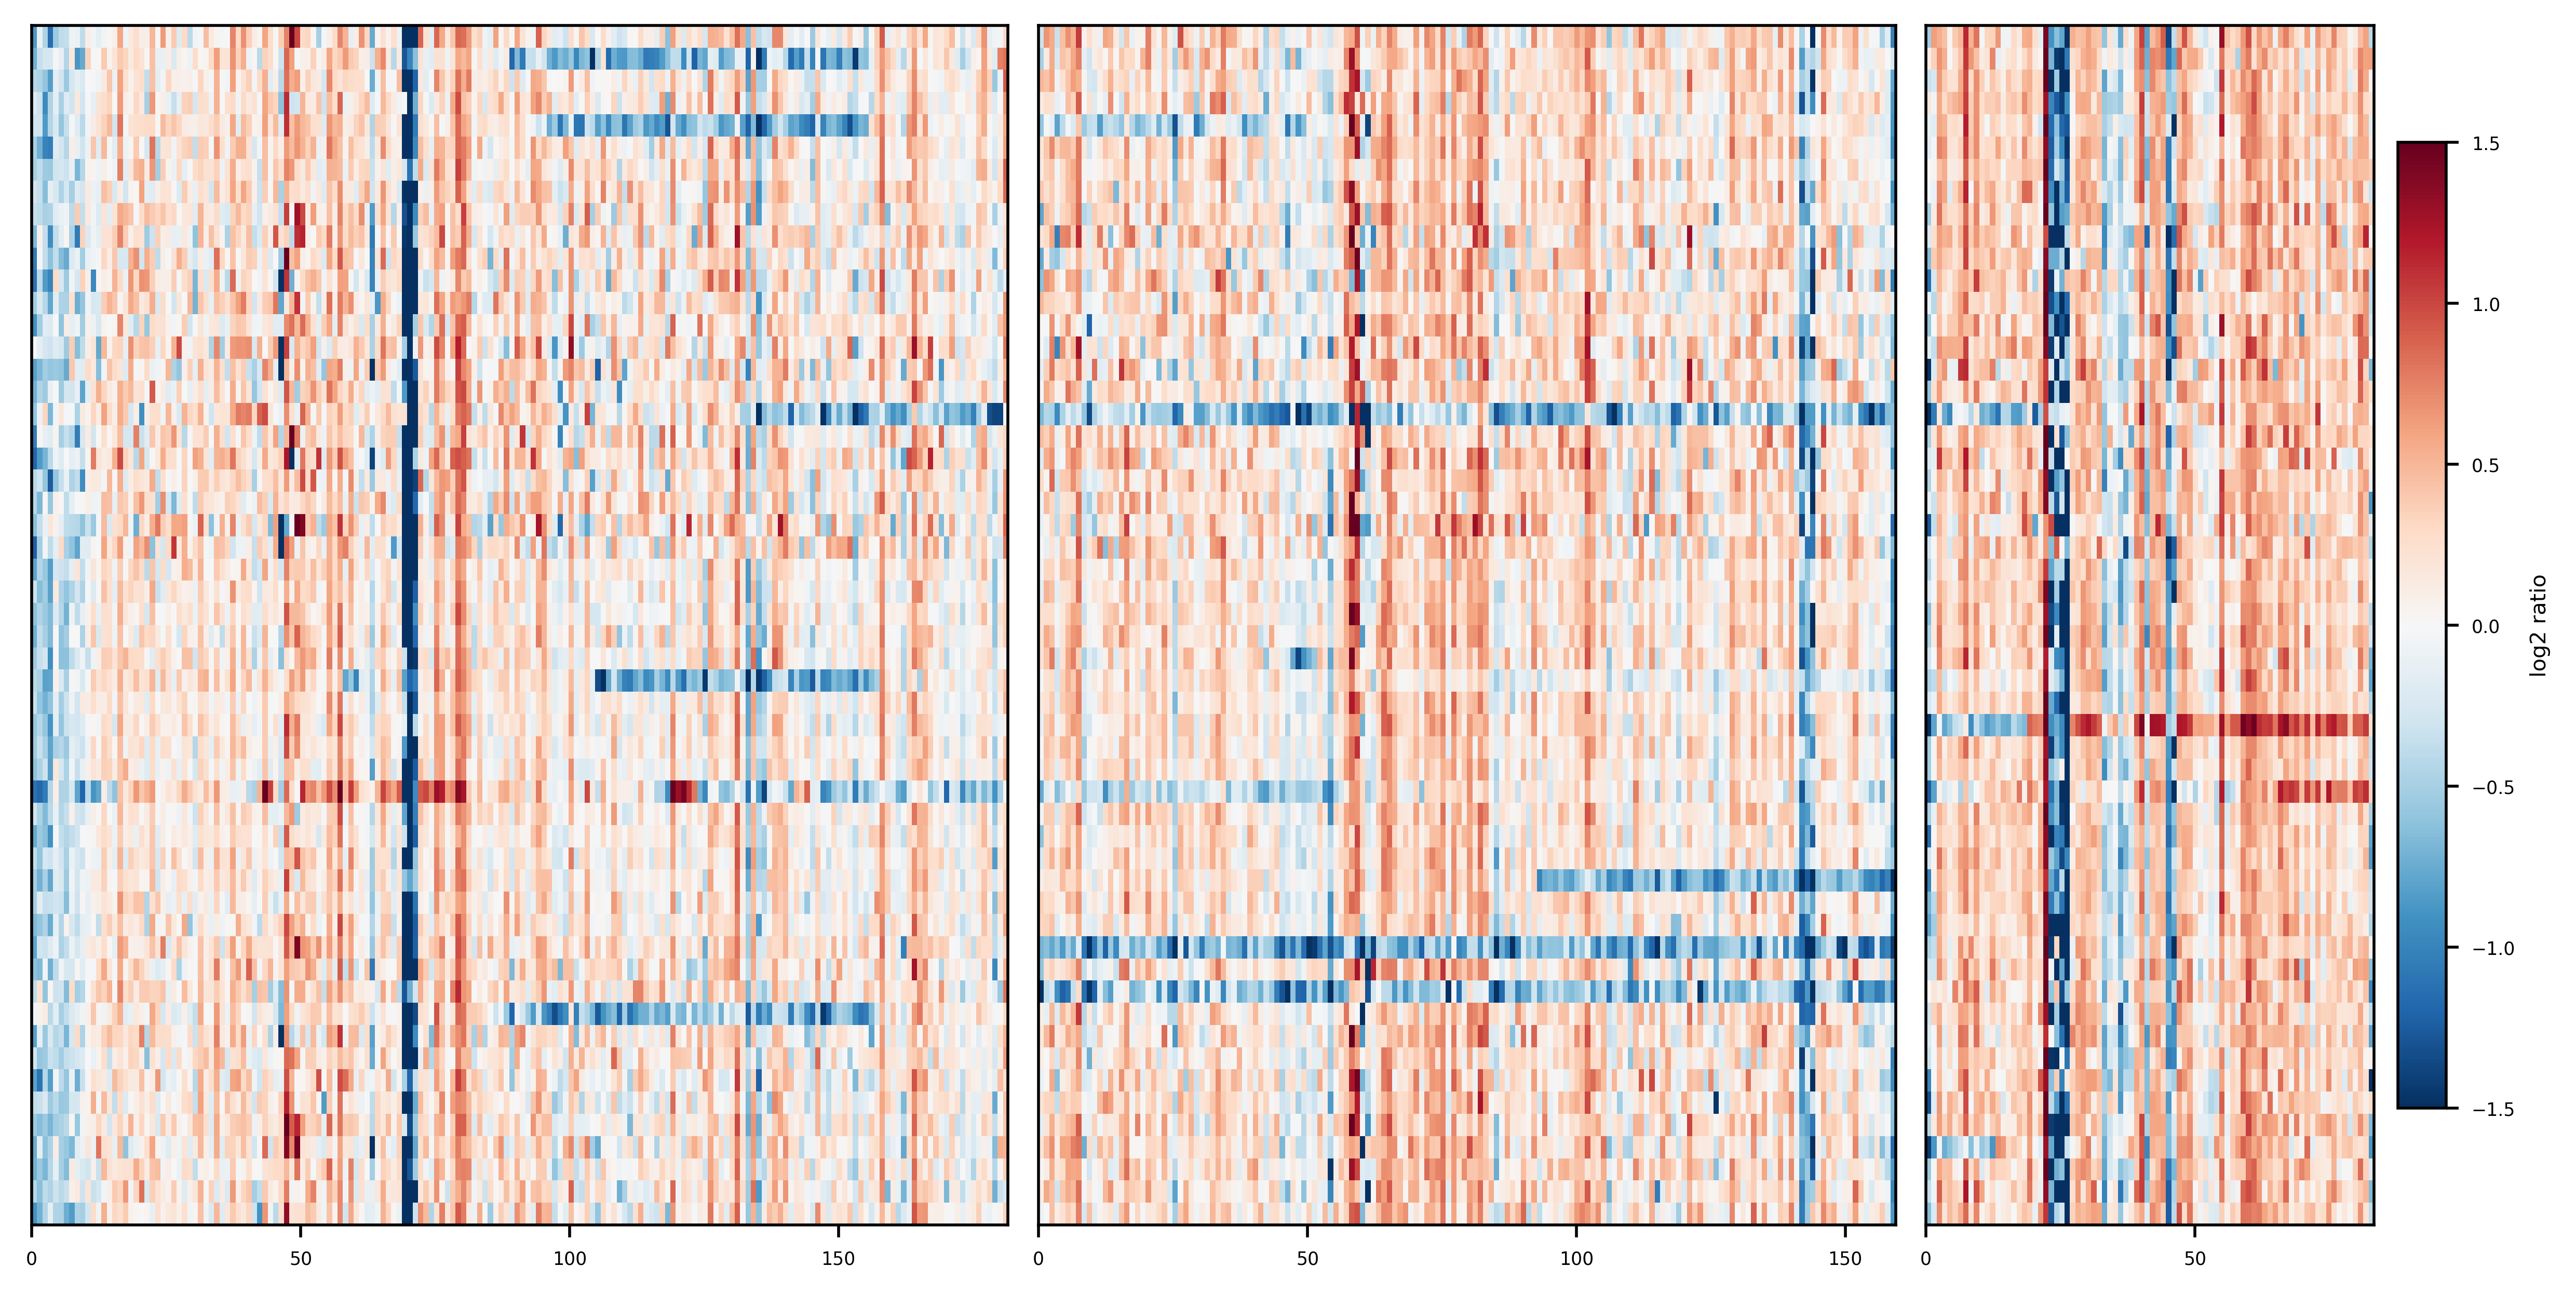

Saved /home/18parkky/data/aml/paper/cnv_calling/cnvkit/6_visualization/cnr_1mb.pdf / .png  (54 samples)


In [24]:
USE_SEGMENTS = False
BIN_SIZE = 1_000_000           # window size (bp); 1-2 Mb works well for arm
                               # -level events, 0.5 Mb for focal ones
VMIN, VMAX = -1.5, 1.5         # color scale limits (log2)
OUT_PREFIX = "cnr_1mb"

# hg38 chromosome lengths for the targeted chromosomes
CHROMS = { "chr5": 181538259, "chr7":159345973, "chr17": 83257441}

# Optional gene landmarks (hg38 approx.) drawn as dashed vertical lines.
# Edit/extend to match your panel; note inv(3)/MECOM rearrangements are
# copy-number NEUTRAL and will not appear as a depth signal here.
GENE_MARKS = {
    "chr5": {"centromere": 49667531},
    "chr7": {"centromere": 49667531},
    "chr17": {"centromere": 22813679},
}

# Known-CNV samples: sample_id -> list of expected events for row annotation.
# Sample IDs must match the .cnr filename stem.
KNOWN_CNVS = {
    "barcode10": [
        {"chrom": "chr5", "start": 67_400_000, "end": 150_400_000, "label": ""},
    ],
    "barcode13": [
        {"chrom": "chr5", "start": 67_400_000, "end": 150_400_000, "label": ""},
    ],
    "barcode34": [
        {"chrom": "chr5",  "start": 0, "end": 181_538_259, "label": ""},
        {"chrom": "chr7",  "start": 0, "end": 159_345_973, "label": ""},
    ],
    "barcode46": [
        {"chrom": "chr7",  "start": 0, "end": 159_345_973, "label": ""},
        {"chrom": "chr17", "start": 0, "end":  83_257_441, "label": ""},
    ],
    "barcode51": [
        {"chrom": "chr5",  "start": 0, "end": 181_538_259, "label": ""},
        {"chrom": "chr7",  "start": 0, "end": 159_345_973, "label": ""},
        {"chrom": "chr17", "start": 0, "end":  83_257_441, "label": ""},
    ],
    "barcode58": [
        {"chrom": "chr7",  "start": 0, "end": 159_345_973, "label": ""},
    ],
    "barcode60": [
        {"chrom": "chr7",  "start": 0, "end": 159_345_973, "label": ""},
    ],
    "barcode61": [
        {"chrom": "chr5", "start": 67_400_000, "end": 131_200_000, "label": ""},
    ],
    "barcode73": [
        {"chrom": "chr17", "start": 0, "end":  83_257_441, "label": ""},
    ],
}

# Optional explicit row order (list of sample IDs). None = known-CNV samples
# first, then the rest alphabetically.
SAMPLE_ORDER = None

# ----------------------------------------------------------------------------


KNOWN_CNVS = dict()
visualize_main()

# Figure 6b. BAF analysis

In [32]:
DIR_baf_out = f'{DIR_cnv_calling}/baf'

In [33]:
grch38_centromere = pd.read_csv(f'{DIR_baf_out}/grch38_centromere.bed', sep='\t', header=None)
grch38_centromere.columns = ['chrom', 'start', 'end', 'region']

In [ ]:
bafs = list()
for PATH_baf in glob.glob(f'{DIR_baf_out}/*baf.tsv'):
    baf = pd.read_csv(PATH_baf, sep='\t')
    baf['SampleID'] = os.path.basename(PATH_baf.split('.')[0].split('_')[-1])
    bafs.append(baf)
bafs = pd.concat(bafs)
bafs.reset_index(inplace=True, drop=True)
print(bafs.shape)

(99658, 8)


In [ ]:
bafs = label_centromere_distance(bafs, grch38_centromere)

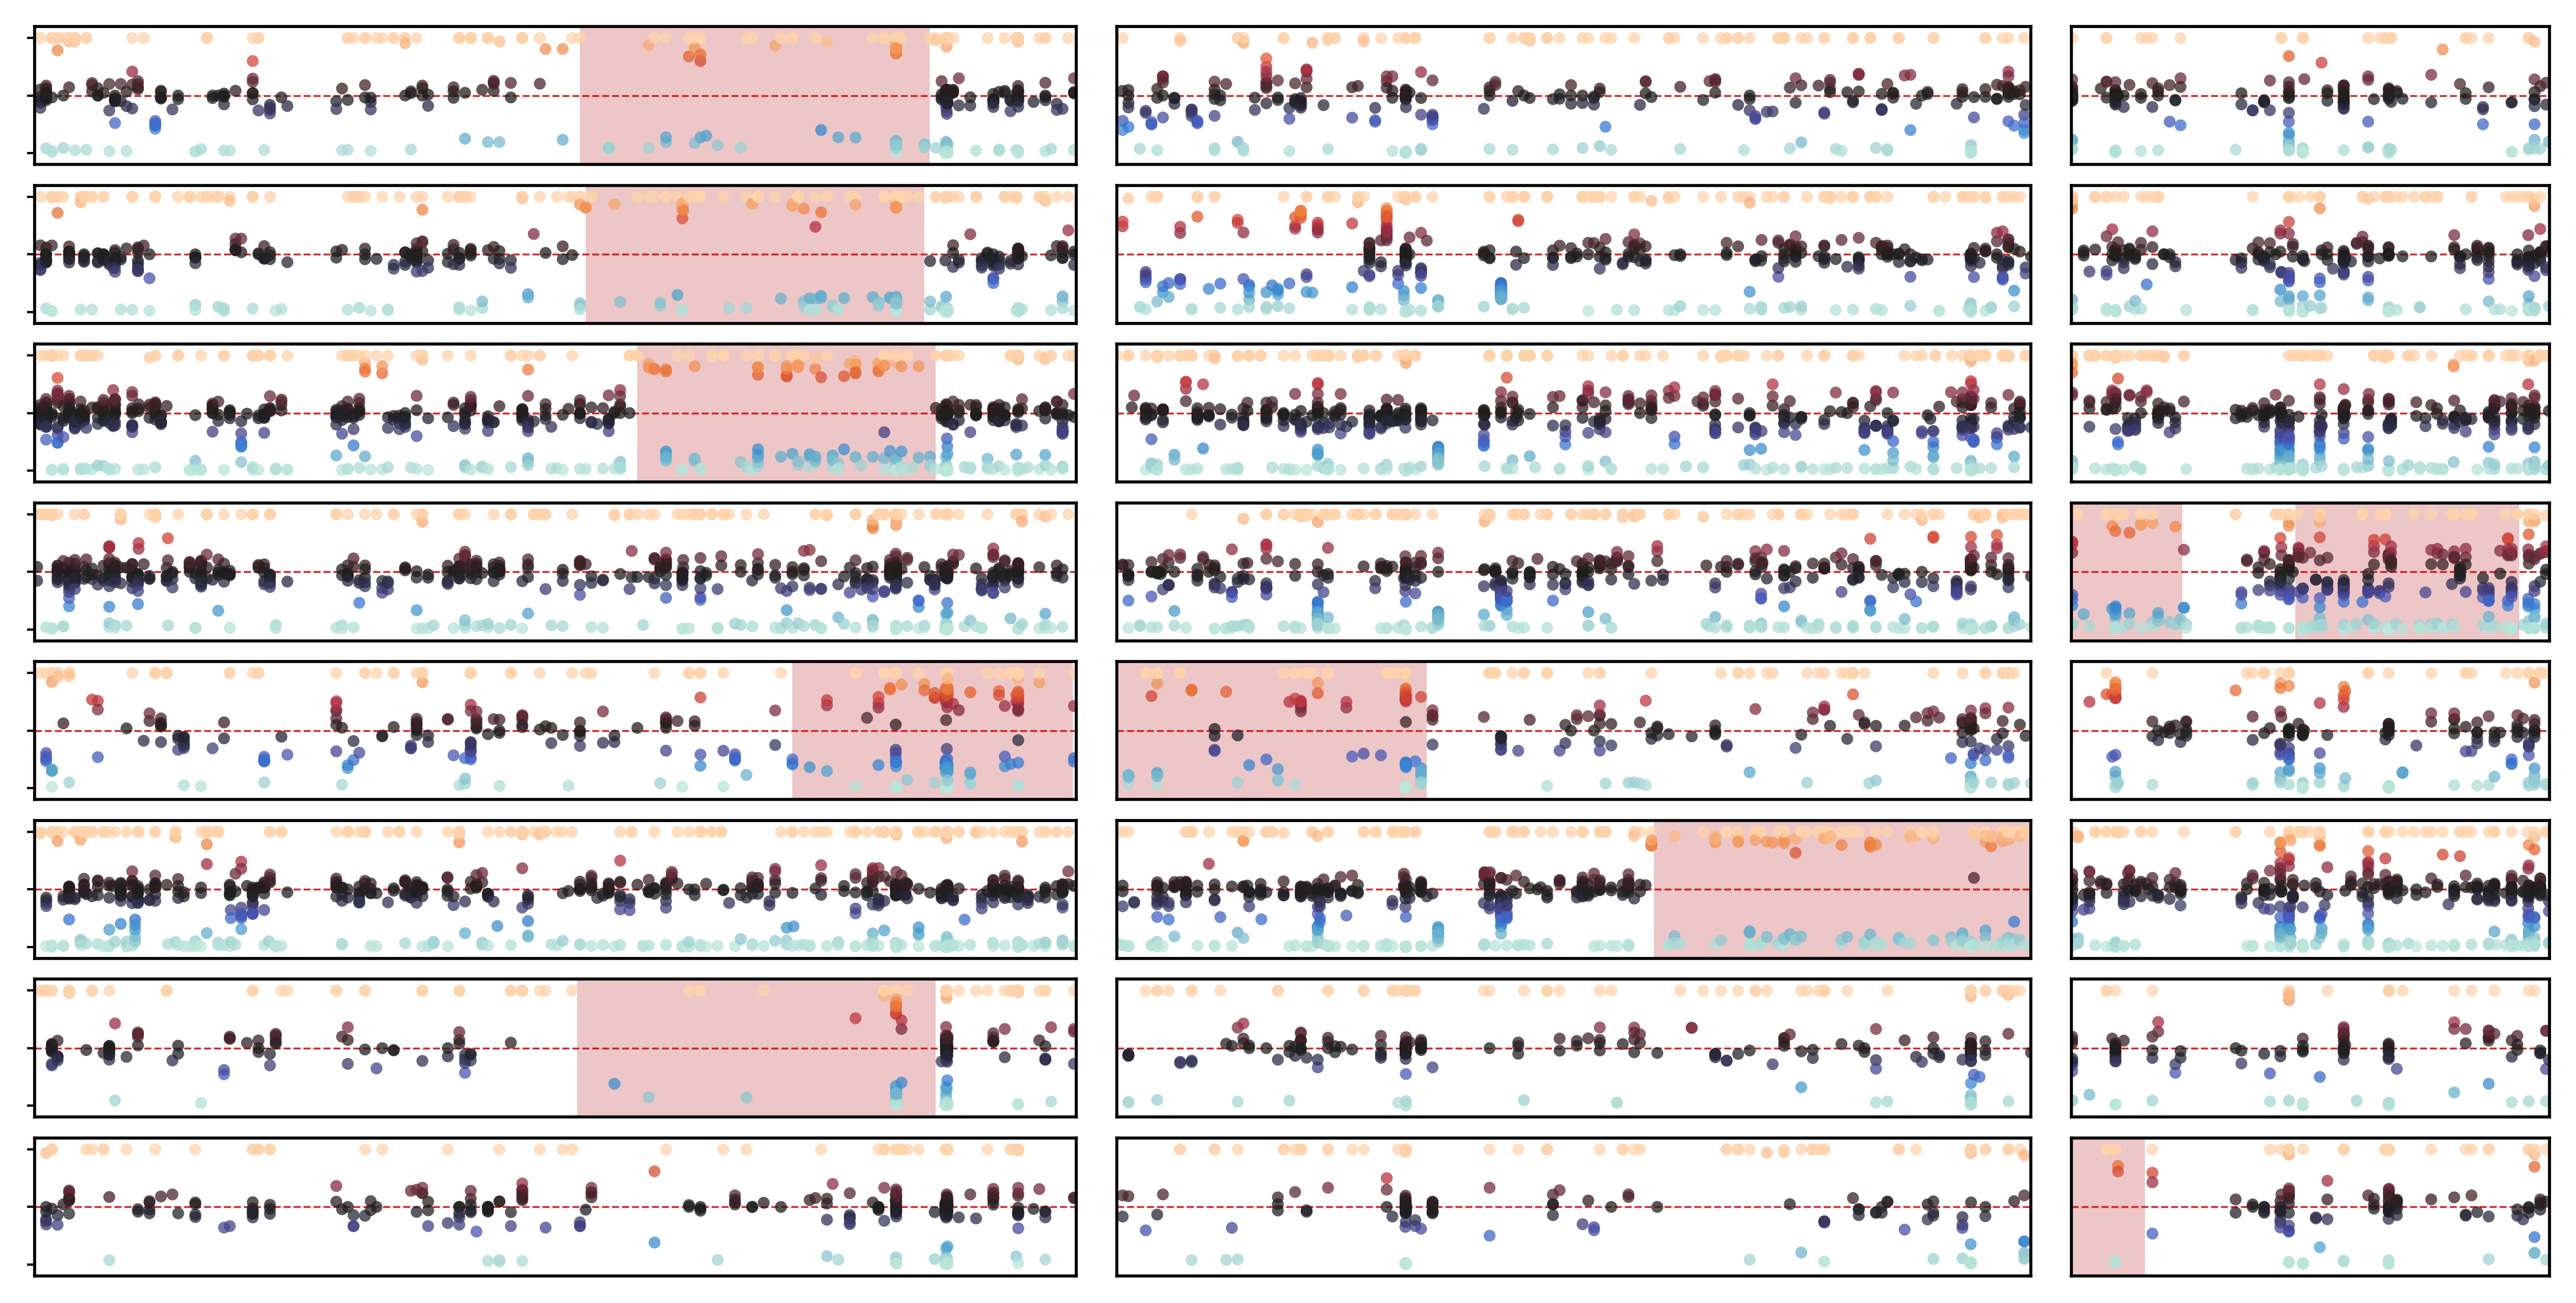

In [ ]:
### Config ─────────────────────────────────────────────
# SampleID   = ['barcode10', 'barcode13', 'barcode34', 'barcode46', 'barcode48', 'barcode51', 'barcode55', 'barcode58', 'barcode60', 'barcode61', 'barcode73']
SampleID   = ['barcode10', 'barcode13', 'barcode46', 'barcode48', 'barcode51', 'barcode55', 'barcode61', 'barcode73']

### CNV overlay config ─────────────────────────────────
CNV_LINE  = dict(color="#f70029", lw=0.7, ls='-', alpha=0, zorder=3)
CNV_SPAN  = dict(color="#b91d24", alpha=0.25, lw=0, zorder=0)
SHOW_SPAN = True     # False → boundary lines only
EDGE_EPS  = 0.1      # Mb; suppress a line that would land on the spine

BIN_SIZE = 1000000
KNOWN_CNVS = {
    "barcode10": [
        {"chrom": "chr5", "start": 95*BIN_SIZE, "end": 156*BIN_SIZE, "label": ""},
    ],
    "barcode13": [
        {"chrom": "chr5", "start": 96*BIN_SIZE, "end": 155*BIN_SIZE, "label": ""},
    ],
    "barcode34": [
        {"chrom": "chr5",  "start": 133*BIN_SIZE, "end": 181.5*BIN_SIZE, "label": ""},
        {"chrom": "chr7",  "start": 0, "end": 159_345_973, "label": ""},
        {"chrom": "chr17",  "start": 176*BIN_SIZE, "end": 20.6*BIN_SIZE, "label": ""},

    ],
    "barcode46": [
        {"chrom": "chr5",  "start": 105*BIN_SIZE, "end": 157*BIN_SIZE, "label": ""},
    ],
    "barcode48": [
        {"chrom": "chr17",  "start": 0.1*BIN_SIZE, "end": 19.3*BIN_SIZE, "label": ""},
        {"chrom": "chr17",  "start": 39*BIN_SIZE, "end": 78*BIN_SIZE, "label": ""},
    ],
    "barcode51": [
        {"chrom": "chr5",  "start": 132*BIN_SIZE, "end": 181*BIN_SIZE, "label": ""},
        {"chrom": "chr7",  "start": 0*BIN_SIZE, "end": 54*BIN_SIZE, "label": ""},
        # {"chrom": "chr17", "start": 0, "end":  83_257_441, "label": ""},
    ],
    "barcode55": [
        {"chrom": "chr7",  "start": 93.6*BIN_SIZE, "end": 159.3*BIN_SIZE, "label": ""},
    ],
    "barcode58": [
        {"chrom": "chr7",  "start": 0, "end": 159_345_973, "label": ""},
    ],
    "barcode60": [
        {"chrom": "chr7",  "start": 0, "end": 159_345_973, "label": ""},
    ],
    "barcode61": [
        {"chrom": "chr5", "start": 94.5*BIN_SIZE, "end": 157*BIN_SIZE, "label": ""},
    ],
    "barcode73": [
        {"chrom": "chr17", "start": 0.16*BIN_SIZE, "end": 12.86*BIN_SIZE, "label": ""},
    ],
}

### ────────────────────────────────────────────────────

CHROMS     = ['chr5', 'chr7', 'chr17']
CHROM_MB   = {'chr5': 181.5, 'chr7': 159.3, 'chr17': 83.3}   # GRCh38 lengths (Mb)
MIN_CEN_D  = 2_000_000
POINT      = dict(s=10, linewidth=0, alpha=0.75, color='#404040', rasterized=True)
MIN_DEPTH = 10
palette_e = sns.color_palette("icefire", as_cmap=True)
### ────────────────────────────────────────────────────

n = len(SampleID)
fig, axes = plt.subplots(
    n, len(CHROMS),
    figsize=(12, 0.75 * n), dpi=500,
    sharey=True, sharex='col', squeeze=False,
    gridspec_kw={'width_ratios': [CHROM_MB[c] for c in CHROMS],
                 'wspace': 0.05, 'hspace': 0.15},
)

for i, sid in enumerate(SampleID):
    d = bafs[(bafs['SampleID'] == sid) &                 # note: == sid, not == SampleID
             (bafs['dist_to_centromere'] > MIN_CEN_D) &
             (bafs['dp'] >= MIN_DEPTH)].copy()
    d['pos_mb'] = d['pos'] / 1e6

    for j, chrom in enumerate(CHROMS):
        ax = axes[i, j]
        sns.scatterplot(data=d[d['chrom'] == chrom], x='pos_mb', y='vaf',
                        hue='vaf', palette=palette_e, legend=None, ax=ax, **POINT)
        ax.axhline(0.5, color='tab:red', lw=0.5, ls='--', zorder=0)

        for reg in KNOWN_CNVS.get(sid, []):
            if reg['chrom'] != chrom:
                continue
            lo, hi = sorted((reg['start'] / 1e6, reg['end'] / 1e6))
            lo, hi = max(lo, 0.0), min(hi, CHROM_MB[chrom])
            if hi <= lo:
                continue
            if SHOW_SPAN:
                ax.axvspan(lo, hi, **CNV_SPAN)
            for x in (lo, hi):
                if EDGE_EPS < x < CHROM_MB[chrom] - EDGE_EPS:
                    ax.axvline(x, **CNV_LINE)
            if reg.get('label'):
                ax.text((lo + hi) / 2, 1.02, reg['label'], fontsize=5,
                        ha='center', va='bottom')
                
        ax.set_xlim(0, CHROM_MB[chrom]); ax.set_ylim(-0.1, 1.1)
        ax.set_xlabel(''); ax.set_ylabel('')
        ax.set_xticks([])
        ax.set_yticks([0.0, 0.5, 1.0])
        ax.tick_params(axis='y', length=2, width=0.6,
                       left=(j == 0), labelleft=False)